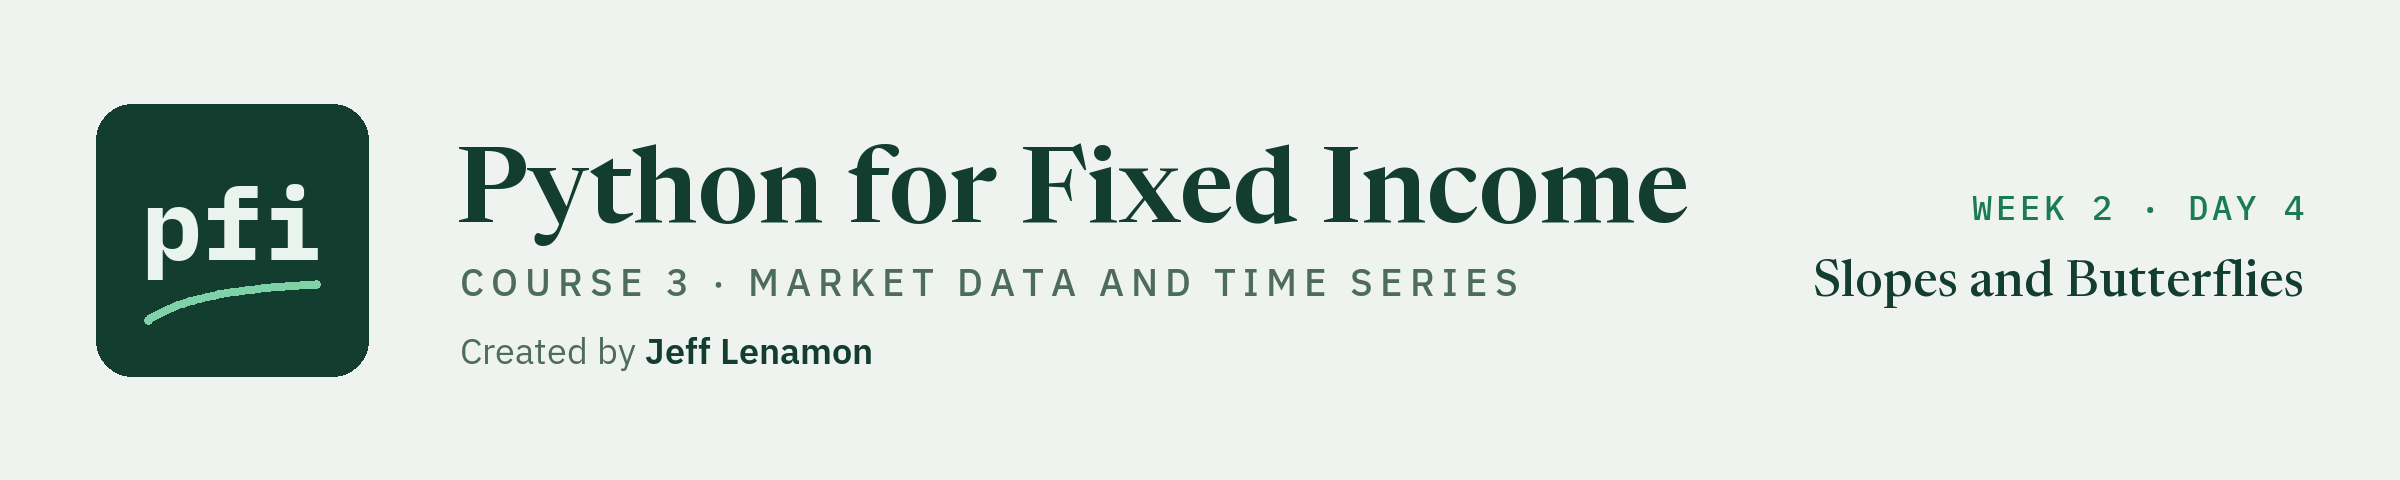

# Slopes and Butterflies

Week 2, Day 4. A curve's shape, in two kinds of number. Today: slopes and butterflies with their signs stated, two functions that compute them, how they moved since 2015, DV01-neutral fly weights from your bondmath, and FRED's own 2s10s against yours.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day4/09_slopes_and_butterflies.ipynb)

A curve is a row of yields on a date: 14 tenors in the Treasury file. A desk talks about its shape in two kinds of number:

* A **slope**: one yield less another, in bp. `2s10s` is the 10 Yr less the 2 Yr.
* A **butterfly** (a fly): a middle yield, the belly, against the two around it, the wings. `2s5s10s` is twice the 5 Yr less the 2 Yr and the 10 Yr.

Each is one line of arithmetic, and each comes with a convention: which yield is subtracted from which, and which sign means what. Get the convention wrong and the number is still plausible, just backwards. Today's AI check is exactly that.

Today you will:

1. Compute three slopes and say what their signs mean.
2. Compute two butterflies, and meet the other sign some desks use.
3. Add `slope_bp` and `butterfly_bp` to `marketdata.py`, with three tests.
4. Follow the slopes and flies from 2015-01-02 to 2026-10-02, with day 8's rolling z-score.
5. Compute the face amounts that make a fly's three DV01s net to zero, with your `bondmath`, and add `fly_weights`.
6. Compare FRED's `T10Y2Y` with your 2s10s, if you have a key.

Every sentence today describes the shape of the curve on a date and how it changed. None says what a shape means for the economy, for policy, or for what comes next.

Q. Set up today's work folder and copy today's three data files into it.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course03_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_09_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_excel_reference.csv", "course3_fred_format_dgs10.json"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_09_i180owgm, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_excel_reference.csv, course3_fred_format_dgs10.json
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp', 'rolling_zscore', 'rolling_percentile_rank']


* `marketdata.py` arrives with the 20 functions of days 1 to 8. Today adds three. `bondmath` is used in section 9.5, for DV01s.

Q. Load the Treasury file as a curve: one row per market date, one column per tenor, yields in percent.

In [7]:
# the date column becomes the index; float_precision="round_trip" reads every number exactly as written
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
print(f"{len(curve):,} market dates, {curve.index[0].date()} to {curve.index[-1].date()}, {curve.shape[1]} tenors")
# the five tenors today uses, from 2026-09-30 to the last market date, as a styled table:
# .style is the pandas version of Excel's Format Cells, .format sets the digits, .format_index writes the dates without a time
(curve.loc["2026-09-30":, ["3 Mo", "2 Yr", "5 Yr", "10 Yr", "30 Yr"]].style
    .format("{:.2f}")
    .format_index("{:%Y-%m-%d}")
    .set_caption("Treasury par yields (%) from 2026-09-30 to the last market date"))

2,940 market dates, 2015-01-02 to 2026-10-02, 14 tenors


,3 Mo,2 Yr,5 Yr,10 Yr,30 Yr
date,,,,,
2026-09-30,4.20,4.88,5.09,5.29,5.64
2026-10-01,4.17,4.78,5.01,5.24,5.61
2026-10-02,4.19,4.83,5.06,5.28,5.63


* 2,940 dates and 14 tenors. On 2026-10-02 the 2 Yr is 4.83, the 5 Yr 5.06, the 10 Yr 5.28, and the 30 Yr 5.63 percent. These five columns have a value on every date of the file.
* A **tenor** is the time to maturity of a point on the curve: 3 Mo, 2 Yr, 5 Yr, 10 Yr, 30 Yr. `.style` turns a table into a formatted one, the way Format Cells does in Excel. The numbers underneath do not change.

## 9.1 Slopes: 2s10s, 5s30s, 3m10y

A slope is named **short tenor first, then long**, and computed as the long yield less the short one, times 100 for bp:

| Name | Formula, yields in percent | Positive means |
| --- | --- | --- |
| `2s10s` | (10 Yr - 2 Yr) x 100 | the 10 Yr yields more than the 2 Yr |
| `5s30s` | (30 Yr - 5 Yr) x 100 | the 30 Yr yields more than the 5 Yr |
| `3m10y` | (10 Yr - 3 Mo) x 100 | the 10 Yr yields more than the 3 Mo |

A positive slope means the curve rises from the short tenor to the long one; a negative slope means it falls. Desks call a negative slope "inverted". In this course that word describes the shape on a date and nothing more.

Q. Compute 2s10s on 2026-10-02 by hand, from the two columns.

In [8]:
# long less short, then x 100: yields in percent, slope in bp
two_tens_bp = (curve.loc["2026-10-02", "10 Yr"] - curve.loc["2026-10-02", "2 Yr"]) * 100
print(f"2s10s on 2026-10-02: {two_tens_bp:.2f} bp")
print(f"the raw number: {float(two_tens_bp)!r}")

2s10s on 2026-10-02: 45.00 bp
the raw number: 45.000000000000014


* 45 bp: the 10 Yr yields 45 bp more than the 2 Yr.
* The raw number shows binary noise in the last digits, the same noise day 8 rounded away before ranking. Yields with two decimals give slopes in whole bp, so the f-string with `:.2f` is the honest way to show them.

Q. All three slopes for every date, as one table. What were they from 30 September to the last market date?

In [9]:
# each slope is one column: long less short, x 100
slopes_by_hand = pd.DataFrame({
    "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100,
    "5s30s": (curve["30 Yr"] - curve["5 Yr"]) * 100,
    "3m10y": (curve["10 Yr"] - curve["3 Mo"]) * 100,
})
(slopes_by_hand.loc["2026-09-30":].style
    .format("{:+.2f}")
    .format_index("{:%Y-%m-%d}")
    .set_caption("Three slopes in bp from 2026-09-30 to the last market date (positive: the longer yield is higher)"))

,2s10s,5s30s,3m10y
date,,,
2026-09-30,+41.00,+55.00,+109.00
2026-10-01,+46.00,+60.00,+107.00
2026-10-02,+45.00,+57.00,+109.00


* In `{:+.2f}`, the `+` always shows the sign, so a positive slope reads `+45.00` and a negative one `-45.00`.
* All three positive on 30 September and on the last market date: on 2026-10-02, 2s10s 45 bp, 5s30s 57 bp, 3m10y 109 bp.
* 2s10s went from 41 bp on 2026-09-30 to 45 bp on 2026-10-02: the 2 Yr fell 5 bp over the two market days and the 10 Yr fell 1 bp. A slope changes when its two yields move by different amounts; both can rise or fall together.

Q. What does a negative slope look like? Find the lowest 2s10s in the file.

In [10]:
# idxmin returns the date of the smallest value
lowest_date = slopes_by_hand["2s10s"].idxmin()
print(f"lowest 2s10s: {slopes_by_hand['2s10s'].min():.2f} bp on {lowest_date.date()}")
curve.loc[lowest_date, ["2 Yr", "10 Yr"]]

lowest 2s10s: -108.00 bp on 2023-07-03


2 Yr     4.94
10 Yr    3.86
Name: 2023-07-03 00:00:00, dtype: float64

* `.idxmin()` returns the date of the smallest value, and `.loc[date, [...]]` picks one row and two columns.
* -108 bp on 2023-07-03: that day the 2 Yr yielded 4.94 percent and the 10 Yr 3.86 percent, so the curve fell from the 2-year point to the 10-year point.

Q. Draw the curve on the last date and on the lowest-2s10s date, so the sign of the slope shows as a shape.

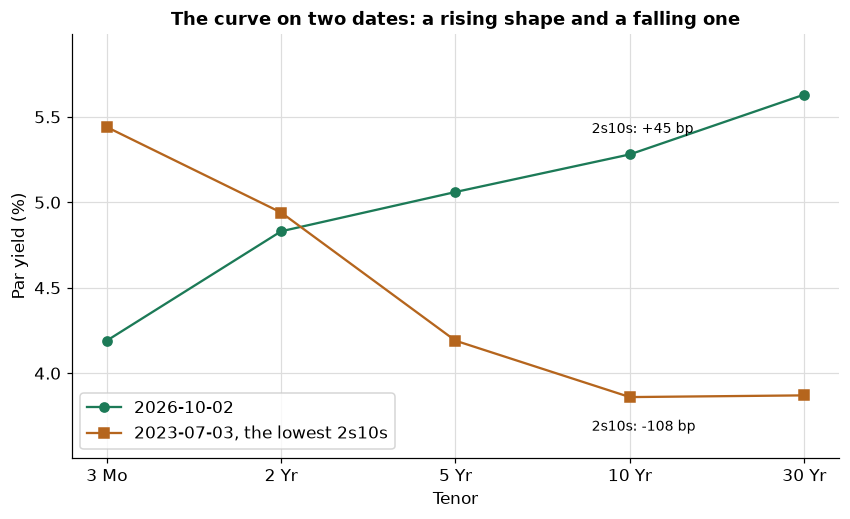

In [11]:
tenor_names = ["3 Mo", "2 Yr", "5 Yr", "10 Yr", "30 Yr"]
positions = list(range(len(tenor_names)))

fig, ax = plt.subplots()
# one line for each date: the yield at each of the five tenors
ax.plot(positions, curve.loc["2026-10-02", tenor_names], marker="o", color="#1c7a57", label="2026-10-02")
ax.plot(positions, curve.loc[lowest_date, tenor_names], marker="s", color="#b5651d", label=f"{lowest_date:%Y-%m-%d}, the lowest 2s10s")
ax.annotate(f"2s10s: {slopes_by_hand.loc['2026-10-02', '2s10s']:+.0f} bp", (3, curve.loc["2026-10-02", "10 Yr"]), textcoords="offset points", xytext=(-25, 14), fontsize=9)
ax.annotate(f"2s10s: {slopes_by_hand.loc[lowest_date, '2s10s']:+.0f} bp", (3, curve.loc[lowest_date, "10 Yr"]), textcoords="offset points", xytext=(-25, -22), fontsize=9)
ax.set_xticks(positions, tenor_names)
ax.set_xlabel("Tenor")
ax.set_ylabel("Par yield (%)")
ax.set_title("The curve on two dates: a rising shape and a falling one")
ax.margins(y=0.2)
ax.legend(loc="lower left")
plt.show()

* The green line rises from the 2 Yr to the 10 Yr, a positive 2s10s. The orange line falls over the same stretch, a negative 2s10s. The sign of the slope is the direction of the line between the two tenors.

## 9.2 Butterflies: 2s5s10s and 5s10s30s

A butterfly compares the belly with the two wings around it. This course computes it as **twice the belly less both wings**, named short, belly, long:

| Name | Formula, yields in percent | Positive means |
| --- | --- | --- |
| `2s5s10s` | (2 x 5 Yr - 2 Yr - 10 Yr) x 100 | the 5 Yr yields more than the average of the 2 Yr and 10 Yr |
| `5s10s30s` | (2 x 10 Yr - 5 Yr - 30 Yr) x 100 | the 10 Yr yields more than the average of the 5 Yr and 30 Yr |

Why "the average of the wings": 2 x belly - short - long is 2 x (belly - (short + long) / 2). So a fly of +10 bp says the belly sits 5 bp above the straight line between the wings. A fly of zero says the three yields lie on a straight line, whatever the slope.

**The other sign.** Some desks quote a butterfly the other way round, wings less belly: (short + long - 2 x belly) x 100. The number is the same size with the opposite sign. Before you compare a fly with anyone else's, ask which one they use. This course uses belly less wings everywhere.

Q. Compute both flies from 30 September to the last market date, and the other desk's sign beside 2s5s10s.

In [12]:
# twice the belly less both wings, x 100
flies_by_hand = pd.DataFrame({
    "2s5s10s": (2 * curve["5 Yr"] - curve["2 Yr"] - curve["10 Yr"]) * 100,
    "5s10s30s": (2 * curve["10 Yr"] - curve["5 Yr"] - curve["30 Yr"]) * 100,
})
# the opposite convention: wings less belly, the same size with the other sign
flies_by_hand["2s5s10s, other sign"] = -flies_by_hand["2s5s10s"]
# + 0.0 shows a rounded -0.0 as 0.0
# a styled table: the format shows the sign; + 0.0 turns a -0.0 into 0.0, as in the line above
(flies_by_hand.loc["2026-09-30":].style
    .format(lambda value: f"{value + 0.0:+.2f}")
    .format_index("{:%Y-%m-%d}")
    .set_caption("Two butterflies in bp from 2026-09-30 to the last market date, and the other desk's sign for 2s5s10s"))

,2s5s10s,5s10s30s,"2s5s10s, other sign"
date,,,
2026-09-30,+1.00,-15.00,-1.00
2026-10-01,-0.00,-14.00,+0.00
2026-10-02,+1.00,-13.00,-1.00


* On 2026-10-02, 2s5s10s is 1 bp: twice 5.06 less 4.83 and 5.28 is 0.01 percent, 1 bp. The 5 Yr sits half a bp above the line between the 2 Yr and the 10 Yr. A desk with the other sign quotes the same curve as -1 bp.
* 5s10s30s is -13 bp: the 10 Yr yields less than the average of the 5 Yr and 30 Yr. Slopes and flies are separate facts about the curve: 5s30s is positive on that date and 5s10s30s is negative.

Q. Draw the two flies and the other sign on both dates as bars, with zero marked.

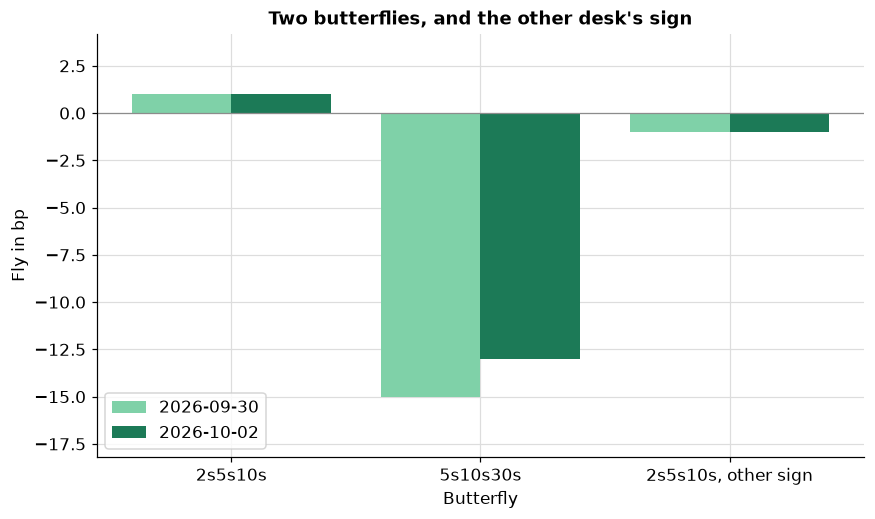

In [13]:
# the two dates the section compares: 2026-09-30 and the last market date
last_two = flies_by_hand.loc[["2026-09-30", "2026-10-02"]]
positions = list(range(len(last_two.columns)))

fig, ax = plt.subplots()
# one bar for each date beside each fly: the earlier date in light green, the later in dark green
ax.bar([p - 0.2 for p in positions], last_two.iloc[0], width=0.4, color="#7fd1a8", label=f"{last_two.index[0]:%Y-%m-%d}")
ax.bar([p + 0.2 for p in positions], last_two.iloc[1], width=0.4, color="#1c7a57", label=f"{last_two.index[1]:%Y-%m-%d}")
ax.axhline(0, color="#8c8c8c", linewidth=0.8)
ax.set_xticks(positions, last_two.columns)
ax.set_axisbelow(True)
ax.margins(y=0.2)
ax.set_xlabel("Butterfly")
ax.set_ylabel("Fly in bp")
ax.set_title("Two butterflies, and the other desk's sign")
ax.legend(loc="lower left")
plt.show()

* Bars above zero mean the belly yields more than the average of the wings. The third group is the same 2s5s10s with the sign flipped: equal size, opposite side of zero.
* The zero line is where the three yields lie on a straight line.

## 9.3 `slope_bp` and `butterfly_bp`

Two functions turn the arithmetic into the module, each with the convention in its docstring, so a reader, a test, or an AI assistant knows which way round the number is. Both take the whole curve and the tenor labels, check the labels are columns, check the dates with day 3's `_check_index`, and return a named series in bp.

Q. Add the two functions to `marketdata.py`. Read both docstrings before you run the cell.

In [14]:
%%writefile -a marketdata.py


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")

Appending to marketdata.py


* The names follow the desk's order: `slope_bp(curve, "2 Yr", "10 Yr")` is 2s10s, `butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")` is 2s5s10s.
* The butterfly docstring says, in its own words, that some desks quote the opposite sign. A docstring is where a convention lives.
* `.rename(...)` names the series after the tenors, so a chart or a table built from it says what it is.

Q. Reload the module, and compute the three slopes and two flies with the functions. Do they equal the hand tables?

In [15]:
# the file changed, so reload before calling the new functions
importlib.reload(md)

slopes = pd.DataFrame({
    "2s10s": md.slope_bp(curve, "2 Yr", "10 Yr"),
    "5s30s": md.slope_bp(curve, "5 Yr", "30 Yr"),
    "3m10y": md.slope_bp(curve, "3 Mo", "10 Yr"),
})
flies = pd.DataFrame({
    "2s5s10s": md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"),
    "5s10s30s": md.butterfly_bp(curve, "5 Yr", "10 Yr", "30 Yr"),
})
# the same arithmetic in the same order, so the numbers are equal exactly, not just close
print(f"slopes equal the hand table: {slopes.equals(slopes_by_hand)}")
print(f"flies equal the hand table: {flies.equals(flies_by_hand[['2s5s10s', '5s10s30s']])}")
print(f"the name slope_bp gives: {md.slope_bp(curve, '2 Yr', '10 Yr').name!r}")

slopes equal the hand table: True
flies equal the hand table: True
the name slope_bp gives: '2 Yr to 10 Yr slope, bp'


Q. What does `slope_bp` do with a tenor the curve does not have?

In [16]:
# "10 Y" is a typing slip for "10 Yr". The error is caught and printed: its traceback would show the work folder's path
try:
    md.slope_bp(curve, "2 Yr", "10 Y")
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: '10 Y' is not a column of curve


* A `ValueError` that names the label, instead of pandas' `KeyError` from deep inside the function. A check that stops, with a message a reader can act on.

Q. Write three tests: the sign of a slope, a fly by hand, and both against Excel's reference rows.

In [17]:
%%writefile -a test_marketdata.py


def test_slope_sign():
    curve = pd.DataFrame({"2 Yr": [4.88, 5.10], "10 Yr": [5.29, 5.00]}, index=pd.to_datetime(["2026-09-30", "2026-10-01"]))
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # positive when the longer yield is higher, negative when it is lower
    assert slope.iloc[0] == pytest.approx(41.0, abs=1e-9)
    assert slope.iloc[1] == pytest.approx(-10.0, abs=1e-9)


def test_butterfly_hand_value():
    curve = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
    # (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
    assert md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9)


def test_butterfly_matches_excel_reference():
    reference = read_reference()
    curve = read_treasury().loc[reference.index]
    fly = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # Excel: =(2*C_t-B_t-D_t)*100 and =(D_t-B_t)*100
    assert ((fly - reference["fly_2s5s10s_bp"]).abs() <= 1e-9).all()
    assert ((slope - reference["slope_2s10s_bp"]).abs() <= 1e-9).all()

Appending to test_marketdata.py


* `test_slope_sign` uses two invented rows, one positive and one negative, so the sign convention is pinned down in both directions.
* `test_butterfly_hand_value` is the arithmetic you can do in your head: (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp.
* `test_butterfly_matches_excel_reference` compares both functions with the 190 rows of 2026 in `course3_excel_reference.csv`, where Excel computed 2s10s as `=(D262-B262)*100` and 2s5s10s as `=(2*C262-B262-D262)*100` (that sheet has the 2 Yr in B, the 5 Yr in C, and the 10 Yr in D), to 1e-9 bp.

Q. Run the tests.

In [18]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......................................                                   [100%]
38 passed in 1.10s



* `38 passed`: days 1 to 8, and today's three.

## 9.4 Slopes and Flies over Time

A slope on one date is one number. Its history says where that number sits. Two views: the slopes themselves over the whole file, then day 8's rolling z-score of 2s10s and 2s5s10s.

Q. Chart the three slopes from 2015, with a line at zero.

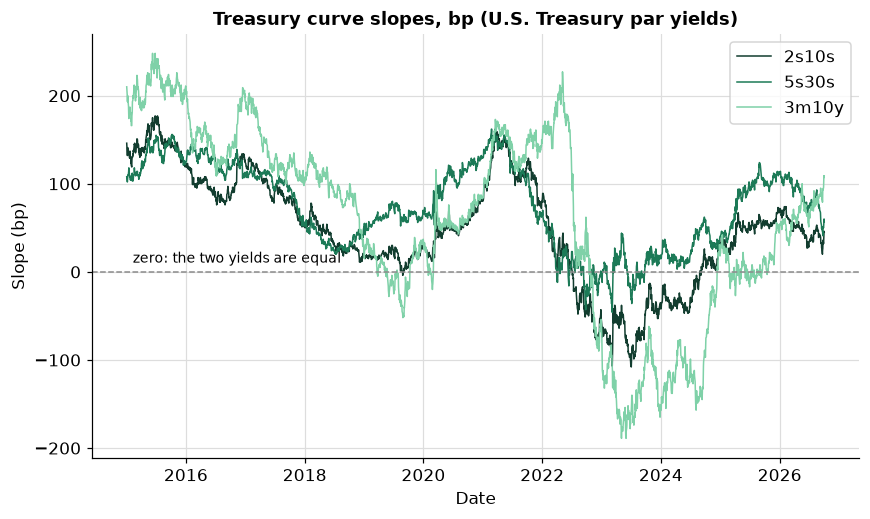

In [19]:
fig, ax = plt.subplots()
for name in slopes.columns:
    ax.plot(slopes.index, slopes[name], label=name, linewidth=1)
# the zero line: above it the longer yield is higher, below it the shorter one is
ax.axhline(0, color="#8c8c8c", linestyle="--", linewidth=1)
ax.annotate("zero: the two yields are equal", (slopes.index[0], 0), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax.set_title("Treasury curve slopes, bp (U.S. Treasury par yields)")
ax.set_xlabel("Date")
ax.set_ylabel("Slope (bp)")
ax.legend()
plt.show()

Q. How many market days was 2s10s below zero, and when?

In [20]:
negative = slopes["2s10s"] < 0
print(f"2s10s below zero on {negative.sum()} of {len(slopes):,} market days")
# a run of negative days: a new run starts each time the True/False value changes
run_id = (negative != negative.shift()).cumsum()
runs = slopes.index.to_series()[negative].groupby(run_id[negative]).agg(["first", "last", "size"])
runs.sort_values("size", ascending=False).head(3).reset_index(drop=True)

2s10s below zero on 544 of 2,940 market days


,first,last,size
0,2022-07-06,2024-08-26,537
1,2019-08-27,2019-08-29,3
2,2022-04-01,2022-04-04,2


* Below zero on 544 of 2,940 market days. 537 of them form one unbroken run, from 2022-07-06 to 2024-08-26. The lowest point, -108 bp on 2023-07-03, is inside that run; the highest, 177 bp, was on 2015-06-26.
* How the runs are found: `negative != negative.shift()` is `True` where the value flips between `True` and `False`, `.cumsum()` counts the flips so each run gets its own number, and `.groupby(...).agg(...)` summarises each run by its first date, last date, and size.
* Exactly zero on 7 days, which counts as neither. Over 2026, 2s10s ran from 20 to 74 bp.
* The other two: 3m10y was below zero on 738 days and 5s30s on 177. Each slope has its own history; one being negative does not make the others so.

Q. Where does 2s10s sit in its own last year? Day 8's `rolling_zscore` over 252 rows, checked against Excel's `STANDARDIZE` column of the reference file.

In [21]:
# day 8: (x - mean of the trailing 252 rows) / their sample standard deviation, today included
z_2s10s = md.rolling_zscore(slopes["2s10s"], window=252)

# Excel computed the same over the same rows: =STANDARDIZE(J262,AVERAGE(J11:J262),STDEV.S(J11:J262))
reference = pd.read_csv("course3_excel_reference.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
gap = (z_2s10s.loc[reference.index] - reference["zscore252_2s10s"]).abs().max()
print(f"largest gap to Excel over {len(reference)} rows: {gap:.1e}")
print(f"2s10s on 2026-10-02: {slopes.loc['2026-10-02', '2s10s']:.2f} bp, z-score {z_2s10s.loc['2026-10-02']:.2f}")

largest gap to Excel over 190 rows: 7.3e-14
2s10s on 2026-10-02: 45.00 bp, z-score -0.51


* Python and Excel agree to 7e-14 over all 190 rows of 2026: a z-score of a slope is just a z-score of a series, and day 8's function needs no change.
* On 2026-10-02, 2s10s was 45 bp, 0.51 standard deviations below the mean of its last 252 market days.

Q. Draw the three longest runs of negative 2s10s on a timeline, and the 2026 z-score with zero marked.

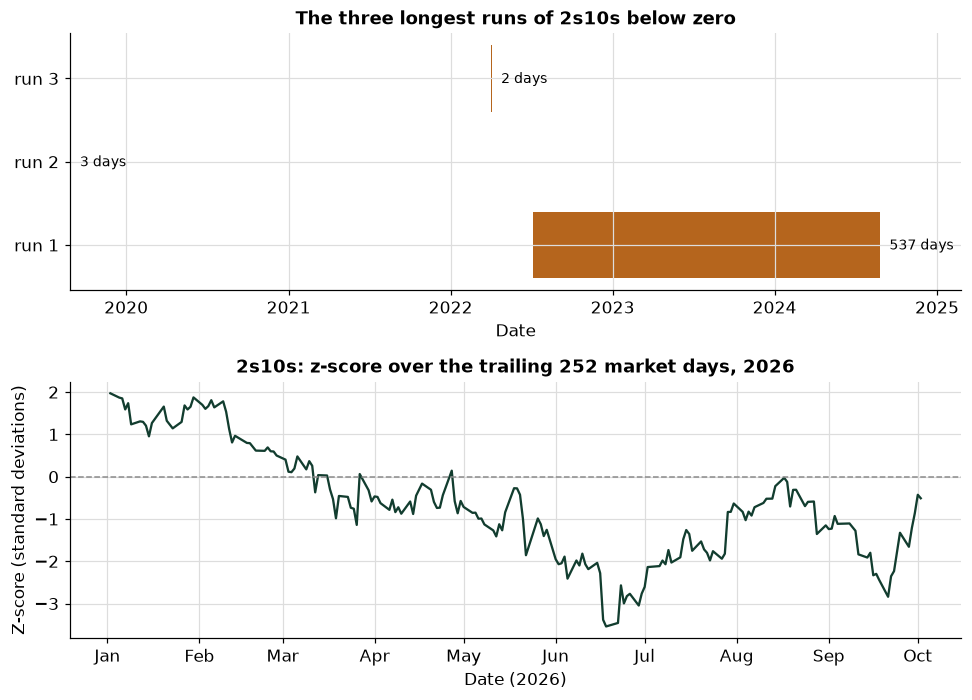

In [22]:
import matplotlib.dates as mdates

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5))
# top: each of the three longest runs as one bar from its first date to its last
longest = runs.sort_values("size", ascending=False).head(3).reset_index(drop=True)
top.barh(range(len(longest)), (longest["last"] - longest["first"]).dt.days, left=mdates.date2num(longest["first"]), color="#b5651d")
for i, run_row in longest.iterrows():
    top.annotate(f"{run_row['size']} days", (mdates.date2num(run_row["last"]), i), textcoords="offset points", xytext=(6, -3), fontsize=9)
top.xaxis_date()
top.set_yticks(range(len(longest)), [f"run {i + 1}" for i in range(len(longest))])
top.set_xlabel("Date")
top.set_title("The three longest runs of 2s10s below zero")
top.margins(x=0.1)
# bottom: the 2026 z-score of 2s10s with zero marked
z_2026 = z_2s10s.loc["2026"]
bottom.plot(z_2026.index, z_2026, color="#123d2f")
bottom.axhline(0, color="#8c8c8c", linestyle="--", linewidth=1)
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
bottom.set_xlabel("Date (2026)")
bottom.set_ylabel("Z-score (standard deviations)")
bottom.set_title("2s10s: z-score over the trailing 252 market days, 2026")
plt.tight_layout()
plt.show()

* Top: each bar spans one unbroken run of negative days, with its length in market days. Bottom: where 2s10s sat in its own last year during 2026, measured from the mean at zero.
* Both describe the history in the file.

Q. The same for 2s5s10s, on one chart with the fly, for 2024 on.

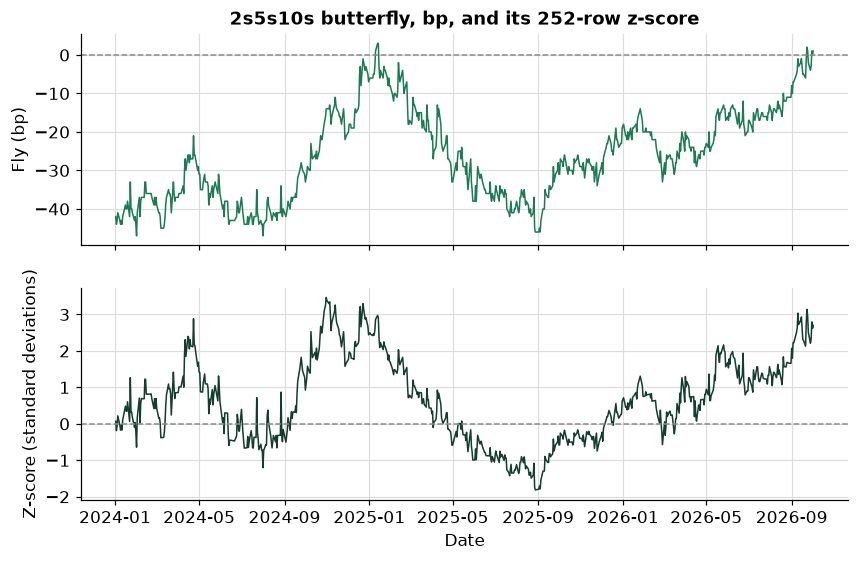

2s5s10s on 2026-10-02: 1.00 bp, z-score 2.70


In [23]:
z_fly = md.rolling_zscore(flies["2s5s10s"], window=252)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
recent = flies.loc["2024":, "2s5s10s"]
top.plot(recent.index, recent, linewidth=1, color="#1c7a57")
top.axhline(0, color="#8c8c8c", linestyle="--", linewidth=1)
top.set_title("2s5s10s butterfly, bp, and its 252-row z-score")
top.set_ylabel("Fly (bp)")
bottom.plot(z_fly.loc["2024":].index, z_fly.loc["2024":], linewidth=1, color="#123d2f")
bottom.axhline(0, color="#8c8c8c", linestyle="--", linewidth=1)
bottom.set_ylabel("Z-score (standard deviations)")
bottom.set_xlabel("Date")
plt.show()
print(f"2s5s10s on 2026-10-02: {flies.loc['2026-10-02', '2s5s10s']:.2f} bp, z-score {z_fly.loc['2026-10-02']:.2f}")

* On 2026-10-02, 2s5s10s was 1 bp, 2.70 standard deviations above the mean of its last 252 market days. Its highest value of 2026 was 2 bp, reached on 1 day.
* Day 8's words still apply: the z-score says where today sits in its own recent history. It is a description of position, never a signal and never a reason to expect a move.

## 9.5 DV01-Neutral Fly Weights, from Your `bondmath`

A fly in bp compares yields. Bonds at the three tenors move by different amounts in price for the same bp move, because their DV01s differ: a 10-year bond's price moves about four times as much as a 2-year bond's. So comparing three bonds, not three yields, needs **weights**: face amounts that make the three DV01s balance.

The published construction this course uses:

* The belly's face is 1 (per unit of face).
* Each wing's face is set so its DV01 is **half the belly's**: w_short = 0.5 x DV01_belly / DV01_short, and w_long = 0.5 x DV01_belly / DV01_long.
* With the belly on one side and both wings on the other, the DV01s **net to zero**.

The DV01s come from Course 2's `bondmath.dv01`, of a **par bond** at each tenor: the coupon equal to that tenor's yield, settlement on 2026-10-02, maturity the same date 2, 5, or 10 years on, semiannual, 30/360. On a coupon date accrued interest is zero and a par bond prices at 100, so each DV01 is the modified duration x 100 / 10,000.

**These weights are arithmetic.** They are the face amounts at which three DV01s net to zero, nothing more. They are not a position, a size, or a trade, and this course never presents them as one.

Q. The DV01 of a par bond at 2, 5, and 10 years on 2026-10-02, per 100 of face per bp.

In [24]:
from datetime import date

settlement = date(2026, 10, 2)
dv01_by_tenor = {}
for tenor, years in [("2 Yr", 2), ("5 Yr", 5), ("10 Yr", 10)]:
    # a par bond: the coupon equals the yield, in percent
    yield_pct = curve.loc["2026-10-02", tenor]
    maturity = bondmath.add_months(settlement, 12 * years)
    dv01_by_tenor[tenor] = bondmath.dv01(settlement, maturity, yield_pct, yield_pct)
    clean = bondmath.price(settlement, maturity, yield_pct, yield_pct)
    print(f"{tenor}: coupon and yield {yield_pct:.2f}%, matures {maturity}, price {clean:.6f}, "
          f"DV01 {dv01_by_tenor[tenor]:.6f} per 100 of face per bp")

2 Yr: coupon and yield 4.83%, matures 2028-10-02, price 100.000000, DV01 0.018848 per 100 of face per bp
5 Yr: coupon and yield 5.06%, matures 2031-10-02, price 100.000000, DV01 0.043693 per 100 of face per bp
10 Yr: coupon and yield 5.28%, matures 2036-10-02, price 100.000000, DV01 0.076925 per 100 of face per bp


* Each prices at 100, to the last digit shown: a par bond on a coupon date.
* DV01s of 0.018848, 0.043693, and 0.076925 price points per 100 of face per bp. The 10-year's is 4.08 times the 2-year's.

Q. Add `fly_weights` to the module, docstring first.

In [25]:
%%writefile -a marketdata.py


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long

Appending to marketdata.py


* The function takes DV01s, not bonds, so it works with any DV01 in one unit: `bondmath`'s, Excel's, or one from a vendor screen.
* It refuses a DV01 that is zero or negative, because there is nothing to balance against.
* Its docstring ends with the sentence that matters: arithmetic, not a position.

Q. Reload, compute the weights, and show the arithmetic: does the belly's DV01 equal the two wings' together?

In [26]:
importlib.reload(md)

w_short, w_belly, w_long = md.fly_weights(dv01_by_tenor["2 Yr"], dv01_by_tenor["5 Yr"], dv01_by_tenor["10 Yr"])
print(f"faces per 1 of belly face: 2 Yr {w_short:.6f}, 5 Yr {w_belly:.6f}, 10 Yr {w_long:.6f}")

# DV01 carried by each face: weight x DV01 per 100 of face
belly_dv01 = w_belly * dv01_by_tenor["5 Yr"]
short_dv01 = w_short * dv01_by_tenor["2 Yr"]
long_dv01 = w_long * dv01_by_tenor["10 Yr"]
print(f"belly {belly_dv01:.6f} = 2 Yr wing {short_dv01:.6f} + 10 Yr wing {long_dv01:.6f}")
print(f"belly less both wings: {belly_dv01 - short_dv01 - long_dv01:.1e}")

faces per 1 of belly face: 2 Yr 1.159049, 5 Yr 1.000000, 10 Yr 0.283995
belly 0.043693 = 2 Yr wing 0.021846 + 10 Yr wing 0.021846
belly less both wings: 0.0e+00


* For each 1 of 5-year face, 1.159049 of 2-year face and 0.283995 of 10-year face. The short wing needs more face than the belly because its DV01 is smaller; the long wing needs less because its DV01 is larger.
* Each wing carries exactly half the belly's DV01, so belly less wings is zero: the three DV01s net out.
* The weights depend on the date: a different curve gives different DV01s and different faces.

Q. Put the three par bonds, their DV01s, their faces, and the DV01 each face carries in one table.

In [27]:
weights_table = pd.DataFrame({
    "yield_pct": [curve.loc["2026-10-02", t] for t in ["2 Yr", "5 Yr", "10 Yr"]],
    "dv01_per_100": [dv01_by_tenor[t] for t in ["2 Yr", "5 Yr", "10 Yr"]],
    "face_per_1_belly": [w_short, w_belly, w_long],
    "dv01_carried": [short_dv01, belly_dv01, long_dv01],
}, index=["2 Yr wing", "5 Yr belly", "10 Yr wing"])
# a styled table: highlight_max shades the biggest value in each column (Excel: Top/Bottom Rules, top 1)
(weights_table.style
    .format({"yield_pct": "{:.2f}", "dv01_per_100": "{:.6f}", "face_per_1_belly": "{:.6f}", "dv01_carried": "{:.6f}"})
    .highlight_max(color="#bfe8d2")
    .set_caption("Par bonds on 2026-10-02: the DV01 of 100 of face, the face for 1 of belly, and the DV01 each face carries"))

,yield_pct,dv01_per_100,face_per_1_belly,dv01_carried
2 Yr wing,4.83,0.018848,1.159049,0.021846
5 Yr belly,5.06,0.043693,1.000000,0.043693
10 Yr wing,5.28,0.076925,0.283995,0.021846


* The last column is the point: each wing carries the same DV01, and the two wings together equal the belly's.
* `highlight_max` shades the largest value in each column, a Top 1 rule in Excel's Conditional Formatting.

Q. Draw the faces and the DV01s they carry.

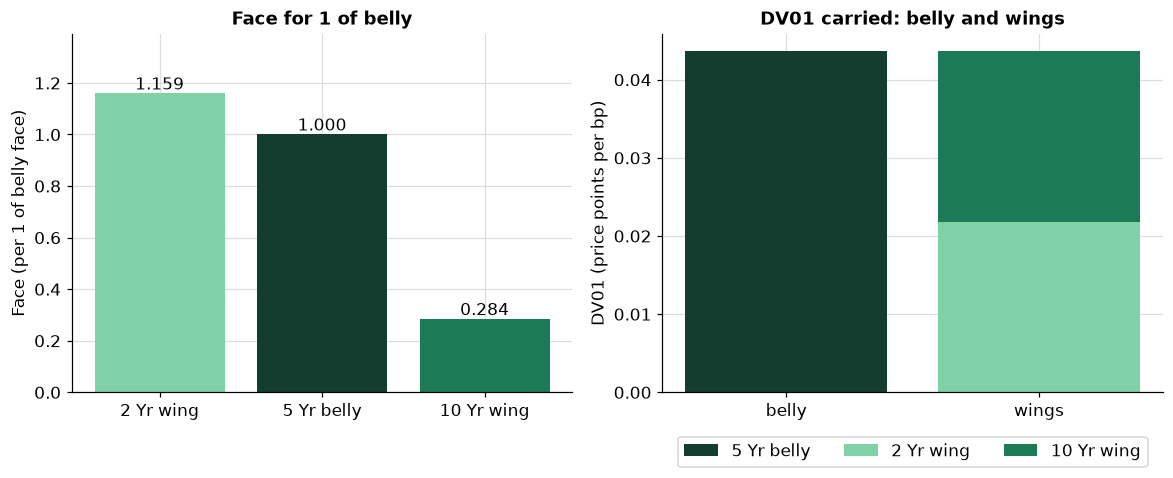

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# left: face amount of each bond for 1 of belly face
bars = axes[0].bar(["2 Yr wing", "5 Yr belly", "10 Yr wing"], weights_table["face_per_1_belly"], color=["#7fd1a8", "#123d2f", "#1c7a57"])
axes[0].bar_label(bars, fmt="%.3f")
axes[0].set_title("Face for 1 of belly")
axes[0].set_ylabel("Face (per 1 of belly face)")
axes[0].set_ylim(0, weights_table["face_per_1_belly"].max() * 1.2)
# right: the belly's DV01 against the two wings' DV01s stacked
axes[1].bar(["belly"], [belly_dv01], color="#123d2f", label="5 Yr belly")
axes[1].bar(["wings"], [short_dv01], color="#7fd1a8", label="2 Yr wing")
axes[1].bar(["wings"], [long_dv01], bottom=[short_dv01], color="#1c7a57", label="10 Yr wing")
axes[1].set_title("DV01 carried: belly and wings")
axes[1].set_ylabel("DV01 (price points per bp)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3)
for ax in axes:
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

* Left: the short wing needs the most face because its DV01 per 100 is the smallest. Right: the two wings stacked reach the same height as the belly, so the three DV01s net to zero.
* This is arithmetic, not a position.

Q. Write the two tests: the weights net to zero, and a DV01 that is not positive is refused.

In [29]:
%%writefile -a test_marketdata.py


def test_fly_weights_neutral():
    # DV01s per 100 of face per bp of par bonds at about 2, 5, and 10 years
    dv01_short, dv01_belly, dv01_long = 0.0186, 0.0436, 0.0778
    w_short, w_belly, w_long = md.fly_weights(dv01_short, dv01_belly, dv01_long)
    assert w_belly == 1.0
    # belly on one side, both wings on the other: the DV01s net to zero, half on each wing
    assert w_belly * dv01_belly - w_short * dv01_short - w_long * dv01_long == pytest.approx(0.0, abs=1e-15)
    assert w_short * dv01_short == pytest.approx(w_long * dv01_long, abs=1e-15)


def test_fly_weights_reject_nonpositive():
    with pytest.raises(ValueError):
        md.fly_weights(0.0186, 0.0, 0.0778)
    with pytest.raises(ValueError):
        md.fly_weights(-0.0186, 0.0436, 0.0778)

Appending to test_marketdata.py


In [30]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 1.11s



* `40 passed`. The test's DV01s are round figures near today's, so it does not depend on the curve.

## 9.6 Live: FRED's `T10Y2Y` against Your 2s10s

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

FRED publishes 2s10s itself, as the series `T10Y2Y`: the 10-year Treasury constant maturity yield less the 2-year, in **percent**, computed from the same Treasury yields as the snapshot. So it is a check on your function: on every date the two share, FRED's value x 100 should equal your 2s10s in bp.

Q. Run the key cell.

In [31]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


Q. Pull `T10Y2Y` from 2015, drop its `.` rows, and compare it with your 2s10s on every common date.

In [32]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    # fred_series (day 2): one GET, the "." rows kept as NaN, a dated series in percent
    live_t10y2y = md.fred_series("T10Y2Y", fred_key, start="2015-01-01")
    print(f"T10Y2Y: {len(live_t10y2y):,} rows, {int(live_t10y2y.isna().sum())} '.' rows, "
          f"{live_t10y2y.index[0].date()} to {live_t10y2y.index[-1].date()}, in percent")
    live_t10y2y = live_t10y2y.dropna()

    # your 2s10s is in bp; FRED's is in percent, so divide yours by 100 to compare
    live_common = live_t10y2y.index.intersection(slopes.index)
    live_gap = (live_t10y2y.loc[live_common] - slopes.loc[live_common, "2s10s"] / 100).abs().max()
    # the checks: every snapshot date up to FRED's last one has a value, FRED has none the snapshot lacks, values equal
    live_span = slopes.loc[:live_t10y2y.index[-1]].index
    live_extra = live_t10y2y.loc[:slopes.index[-1]].index.difference(slopes.index)
    assert live_span.isin(live_common).all(), "a snapshot date has no T10Y2Y value"
    assert len(live_extra) == 0, "T10Y2Y has a date the snapshot does not"
    assert live_gap <= 1e-9, "T10Y2Y and your 2s10s disagree"
    print(f"{len(live_common):,} dates in both, largest gap {live_gap:.1e} percent")
    print(f"T10Y2Y on its last date: {live_t10y2y.iloc[-1]:.2f} percent, {live_t10y2y.iloc[-1] * 100:.0f} bp")

Live cell skipped: no FRED key was found. Every other cell runs without one.


* The saved output is the skip message, because the saved run had no key.
* **With your key** you will see the row count of `T10Y2Y` since 2015, its `.` rows (the weekdays the bond market had no curve, the same days the Treasury file has no row), its first and last dates, then the check line: every date the two share, with the largest gap between FRED's value and yours divided by 100. The last line is FRED's latest 2s10s, which may be a day or two past the snapshot.
* The cell divides your bp by 100 rather than multiplying FRED's percent by 100: either works, and the comparison is in the unit FRED publishes.

## Excel Side by Side

Every slope and fly is one formula in Excel, written once and filled down. Every line below was tested in Excel (16.0 build 20430, 2026-10-04) on the Treasury file opened in Excel, where the columns are E `3 Mo`, I `2 Yr`, K `5 Yr`, M `10 Yr`, and O `30 Yr`.

| Job | Python | Excel, row 2, filled down (tested) | Excel on 2026-10-02 |
| --- | --- | --- | --- |
| 2s10s | `md.slope_bp(curve, "2 Yr", "10 Yr")` | `=(M2-I2)*100` | 45 bp |
| 5s30s | `md.slope_bp(curve, "5 Yr", "30 Yr")` | `=(O2-K2)*100` | 57 bp |
| 3m10y | `md.slope_bp(curve, "3 Mo", "10 Yr")` | `=(M2-E2)*100` | 109 bp |
| 2s5s10s | `md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")` | `=(2*K2-I2-M2)*100` | 1 bp |
| 5s10s30s | `md.butterfly_bp(curve, "5 Yr", "10 Yr", "30 Yr")` | `=(2*M2-K2-O2)*100` | -13 bp |
| z-score of 2s10s | `md.rolling_zscore(slopes["2s10s"], 252)` | `=STANDARDIZE(J262,AVERAGE(J11:J262),STDEV.S(J11:J262))` (reference file) | -0.51 |

**The slope column.** Open `treasury_par_yields.csv` in Excel. In P1 type `2s10s`, in P2 type `=(M2-I2)*100`, and fill it down to row 2941: the 10 Yr in M less the 2 Yr in I, times 100, exactly the order `slope_bp` uses. On the last row the formula reads `=(M2941-I2941)*100`. Over all 2,940 rows the five columns equal Python's exactly, on every row.

**The fly column.** In Q2, `=(2*K2-I2-M2)*100`: twice the 5 Yr in K, less the 2 Yr in I and the 10 Yr in M. The `2*` is on the belly only, and each wing has its own minus sign. Brackets in the wrong place, `=(2*K2-(I2-M2))*100`, turn the long wing's minus into a plus: that is today's AI check.

**The column letters.** The docstrings of `slope_bp` and `butterfly_bp` give these same formulas, with the letters of the Treasury file opened in Excel. A formula is only as right as its column letters: on a sheet laid out any other way, check the header row before you fill down.

**DV01 and the weights, Course 2's way.** One column per tenor: PRICE in row 1, the accrued formula in row 2, MDURATION in row 3, and the DV01 `=B3*(B1+B2)/10000` in row 4. For the 5-year par bond, column C:

| Row | Excel (tested) | Excel returns |
| --- | --- | --- |
| 1 | `=PRICE(DATE(2026,10,2),DATE(2031,10,2),5.06/100,5.06/100,100,2,0)` | 100.000000 |
| 2 | `=100*5.06/100/2*COUPDAYBS(DATE(2026,10,2),DATE(2031,10,2),2,0)/COUPDAYS(DATE(2026,10,2),DATE(2031,10,2),2,0)` | 0.0 |
| 3 | `=MDURATION(DATE(2026,10,2),DATE(2031,10,2),5.06/100,5.06/100,2,0)` | 4.369256 |
| 4 | `=C3*(C1+C2)/10000` | 0.043693 |

With the 2-year in column B and the 10-year in column D, the weights are `=0.5*C4/B4` and `=0.5*C4/D4` in B6 and C6, and the net `=C4-B6*B4-C6*D4` returns 0.0.

Q. Do `bondmath` and Excel agree on the DV01s and the weights? The Excel values are typed in from the test.

In [33]:
# what Excel returned for =MDURATION(...)*(PRICE(...)+accrued)/10000, and for =0.5*C4/B4 and =0.5*C4/D4
excel_dv01 = {"2 Yr": 0.0188484493125592, "5 Yr": 0.04369256053835138, "10 Yr": 0.07692484191007969}
excel_weights = (1.159049209136741, 0.28399512727907356)

dv01_gap = max(abs(dv01_by_tenor[t] - excel_dv01[t]) for t in excel_dv01)
weight_gap = max(abs(w_short - excel_weights[0]), abs(w_long - excel_weights[1]))
print(f"largest DV01 gap to Excel: {dv01_gap:.1e} per 100 of face per bp")
print(f"largest weight gap to Excel: {weight_gap:.1e}")

largest DV01 gap to Excel: 2.1e-17 per 100 of face per bp
largest weight gap to Excel: 6.7e-16


* Both within 1e-9, the tolerance the course set for weights: your `bondmath` and Excel's MDURATION and PRICE give the same DV01s, so they give the same weights.

## Save the Day with Git

Today's Git step is about a data file. Git diffs a CSV line by line, like code, so a changed number shows up as one line out and one line in. First commit the module and the tests, then the file, then make a mistake in it on purpose and read the diff.

Q. Set up the repository and commit today's two files.

In [34]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [35]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_09_i180owgm and nowhere else


In [36]:
# the module and its tests, as they stand at the end of today
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Add slope_bp, butterfly_bp, and fly_weights with five tests" -m "Slopes are long less short, flies are twice the belly less the wings, both in bp from yields in percent."
!git -C "{work}" log --oneline

0c0cce4 Add slope_bp, butterfly_bp, and fly_weights with five tests


Q. Write the 2026 slopes to `slopes_2026.csv` and commit it.

In [37]:
# slopes from two-decimal yields are whole bp; two decimals in the file drop the binary noise
# lineterminator="\n" gives the same file on Windows, Mac, and Colab
slopes.loc["2026"].to_csv("slopes_2026.csv", float_format="%.2f", lineterminator="\n")
print(Path("slopes_2026.csv").read_text(encoding="utf-8").splitlines()[:3])

['date,2s10s,5s30s,3m10y', '2026-01-02,72.00,112.00,54.00', '2026-01-05,71.00,114.00,53.00']


In [38]:
!git -C "{work}" add slopes_2026.csv
!git -C "{work}" commit -q -m "Add slopes_2026.csv, the 2026 slopes in bp"
!git -C "{work}" log --oneline

2e45b25 Add slopes_2026.csv, the 2026 slopes in bp
0c0cce4 Add slope_bp, butterfly_bp, and fly_weights with five tests


Q. Now the mistake: a later cell rewrites the file with the sign of one 2s10s flipped. Run it, then ask Git what changed.

In [39]:
# read the file back, flip one value's sign by mistake, and write it again the same way
edited = pd.read_csv("slopes_2026.csv", index_col="date")
edited.loc["2026-09-30", "2s10s"] = -edited.loc["2026-09-30", "2s10s"]
edited.to_csv("slopes_2026.csv", float_format="%.2f", lineterminator="\n")
print(f"2s10s on 2026-09-30 is now {edited.loc['2026-09-30', '2s10s']:.2f} bp")

2s10s on 2026-09-30 is now -41.00 bp


In [40]:
# M marks a tracked file that changed; diff shows the lines that differ
!git -C "{work}" status --short slopes_2026.csv
!git -C "{work}" diff slopes_2026.csv

 M slopes_2026.csv


diff --git a/slopes_2026.csv b/slopes_2026.csv
index 38b2fe8..08d6126 100644
--- a/slopes_2026.csv
+++ b/slopes_2026.csv
@@ -186,6 +186,6 @@ date,2s10s,5s30s,3m10y
 2026-09-25,36.00,51.00,93.00
 2026-09-28,32.00,50.00,96.00
 2026-09-29,37.00,53.00,101.00
-2026-09-30,41.00,55.00,109.00
+2026-09-30,-41.00,55.00,109.00
 2026-10-01,46.00,60.00,107.00
 2026-10-02,45.00,57.00,109.00


* One line out (`-`), one line in (`+`), the date at the start of each: 2s10s on 2026-09-30 went from 41.00 to -41.00. The rest of the file is unchanged, so Git shows only that line and the lines around it.
* Reading a data file's diff before committing is how a slip like this is caught: a rerun that should change nothing, or one number, shows exactly what moved.

Q. Undo the mistake with day 7's `git restore`, and check the file is back as committed.

In [41]:
# restore puts the committed version back; an empty status and diff mean nothing differs
!git -C "{work}" restore slopes_2026.csv
!git -C "{work}" status --short slopes_2026.csv
!git -C "{work}" diff --stat

In [42]:
print(f"2s10s on 2026-09-30 in the file: {pd.read_csv('slopes_2026.csv', index_col='date').loc['2026-09-30', '2s10s']:.2f} bp")

2s10s on 2026-09-30 in the file: 41.00 bp


* No output from `status` or `diff`: the file is the committed one again, and 2s10s on 2026-09-30 is back to its value.

## Bring It Home

Add today's three functions and five tests to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** Go to your folder and open the two files. The tests read `treasury_par_yields.csv` (copied on day 4) and `course3_excel_reference.csv` (day 6) from it; there is nothing new to copy today.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code marketdata.py
code test_marketdata.py
```

**Step 2.** Paste the code of the two `%%writefile -a marketdata.py` cells (sections 9.3 and 9.5), without their first lines, at the end of `marketdata.py`, and the two `%%writefile -a test_marketdata.py` cells at the end of `test_marketdata.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_marketdata.py
```

```
40 passed
```

**Step 4.** Read the diff, then commit.

```powershell
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Add slope_bp, butterfly_bp, and fly_weights with five tests" -m "Slopes are long less short, flies are twice the belly less the wings, both in bp from yields in percent."
git log --oneline -3
```

**If a test fails**, compare your files with the cells. A failing `test_butterfly_matches_excel_reference` with every other test passing usually means the reference file is missing from the folder.

**In Colab**, download `marketdata.py` and `test_marketdata.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Compute 2s10s, 5s30s, and 3m10y in bp, named short then long, and say what each sign means.
* Compute 2s5s10s and 5s10s30s as twice the belly less the wings, and convert to the other sign some desks use.
* Use `slope_bp` and `butterfly_bp`, tested by hand and against Excel's reference rows.
* Describe a slope's history and where it sits in its last 252 market days, with day 8's z-score.
* Compute DV01-neutral fly weights from par-bond DV01s with `bondmath` and `fly_weights`, and say why they are arithmetic, not a position.
* Check your 2s10s against FRED's `T10Y2Y`.
* Read `git diff` on a data file, and restore it.

Tomorrow, day 10, puts every measure of the week into one table, `summary_table`, as of one date, and uses it on three years of the curve, its slopes and flies, and the synthetic spreads.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use the second set of tenors: the 5 Yr, 10 Yr, and 30 Yr, and the 3 Mo. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the curve and the Excel reference rows, and defines `check`, a small function that marks your answers.

In [43]:
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
reference = pd.read_csv("course3_excel_reference.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. With `md.butterfly_bp`, compute 5s10s30s for every date and store its value on 2026-10-02 in **ex1_fly**, in bp. Then, with `md.slope_bp`, compute 3m10y for the market dates of 2026, store its lowest value in **ex1_low**, in bp, and the date of that value as text, `YYYY-MM-DD`, in **ex1_low_date**.

In [44]:
ex1_fly = ...
ex1_low = ...
ex1_low_date = ...

In [45]:
check("Exercise 1 5s10s30s on 2026-10-02", ex1_fly, -12.9999999999999)
check("Exercise 1 lowest 3m10y of 2026", ex1_low, 30.00000000000003)
check("Exercise 1 its date", ex1_low_date, "2026-02-27")

Exercise 1 5s10s30s on 2026-10-02: not attempted yet
Exercise 1 lowest 3m10y of 2026: not attempted yet
Exercise 1 its date: not attempted yet


### Exercise 2

Q. Compute the DV01-neutral weights for a 5s10s30s fly on 2026-10-02: par bonds at 5, 10, and 30 years (coupon equal to the yield, settlement 2026-10-02, maturity the same date that many years on), DV01s from `bondmath.dv01`, weights from `md.fly_weights`. Store the 5-year wing's face in **ex2_w_short** and the 30-year wing's in **ex2_w_long**, each per 1 of 10-year face.

In [46]:
ex2_w_short = ...
ex2_w_long = ...

In [47]:
check("Exercise 2 the 5-year wing", ex2_w_short, 0.8802967938049596)
check("Exercise 2 the 30-year wing", ex2_w_long, 0.2670293403095496)

Exercise 2 the 5-year wing: not attempted yet
Exercise 2 the 30-year wing: not attempted yet


### Exercise 3

Q. Add a function to your module. `curve_shape(curve_row)` takes one date's row of the curve (a Series, such as `curve.loc["2026-10-02"]`) and returns `"positive"`, `"zero"`, or `"negative"` for its 2s10s. Write the docstring first, with the units and the convention. Round the slope in bp to 6 decimals before comparing it with zero, and raise `ValueError` if the 2 Yr or the 10 Yr is missing. Then add a test, `test_curve_shape_labels`, with three invented rows, one of each label, and the `ValueError`. Run pytest, reload the module, and store the labels for 2023-07-03, 2024-08-30, and 2026-10-02, in that order, as a list in **ex3_labels**.

Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [48]:
%%writefile -a marketdata.py


# Exercise 3: write curve_shape(curve_row) below this line

Appending to marketdata.py


In [49]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_curve_shape_labels() below this line

Appending to test_marketdata.py


In [50]:
# run pytest, reload the module, then call your function on the three dates
ex3_labels = ...

In [51]:
check("Exercise 3 the three labels", ex3_labels, ['negative', 'zero', 'positive'])

Exercise 3 the three labels: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a butterfly function, and you give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is fly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than the
    average of the wings.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, and it contains one bug.

In [52]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def fly_bp(curve, short, belly, long):
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is fly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than the
    average of the wings.
    """
    # the belly counts twice; the wings come off it
    return (2 * curve[belly] - (curve[short] - curve[long])) * 100

Q. Predict before you run the next cell: by hand, (2 x 5.09 - 4.88 - 5.29) x 100 is 1 bp. What will `fly_bp` return for that row? Read the function's last line.

In [53]:
hand = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
print(f"fly_bp on the hand row: {fly_bp(hand, '2 Yr', '5 Yr', '10 Yr').iloc[0]:.2f} bp")

fly_bp on the hand row: 1059.00 bp


Q. Test the function against its docstring before you trust it: a hand value and Excel's reference row for 2026-10-02.

In [54]:
# the test, written from the docstring before the code is trusted
hand = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
# by hand: (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
assert fly_bp(hand, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9), "not the hand value"
# Excel's =(2*C_t-B_t-D_t)*100 on 2026-10-02, from the reference file
excel_fly = reference.loc["2026-10-02", "fly_2s5s10s_bp"]
assert fly_bp(curve.loc[["2026-10-02"]], "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(excel_fly, abs=1e-9), "not Excel's value"
print("The fly matches the hand value and Excel's reference row")

AssertionError: not the hand value

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store `fly_bp` of the hand row, `fly_bp(hand, "2 Yr", "5 Yr", "10 Yr").iloc[0]`, in **ex4_hand**, and its value on 2026-10-02, `fly_bp(curve, "2 Yr", "5 Yr", "10 Yr").loc["2026-10-02"]`, in **ex4_asof**.

In [55]:
# fix the function above and run the test again, then store the two answers
ex4_hand = ...
ex4_asof = ...

In [56]:
check("Exercise 4 the hand row", ex4_hand, 1.0)
check("Exercise 4 on 2026-10-02", ex4_asof, 0.9999999999998899)

Exercise 4 the hand row: not attempted yet
Exercise 4 on 2026-10-02: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```